In [2]:
import pandas as pd

# Exibe todas as colunas sem ocultar nenhuma (sem '...')
pd.set_option('display.max_columns', None)

# Exibe o texto completo dentro de cada célula sem cortar strings longas
pd.set_option('display.max_colwidth', None)

# Define quantas linhas exibir (None para todas, ou um número como 100)
pd.set_option('display.max_rows', None)

# Impede o Pandas de quebrar a tabela em múltiplos blocos de linhas
pd.set_option('display.expand_frame_repr', False)

# Define a largura máxima do console de saída
pd.set_option('display.width', 1000)

Arquivo carregado: data/prova_cn.csv
Total de estudantes: 109
Turmas encontradas: ['2a', '2b', '2c', '2d']
Questões analisadas (29): ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28']


                 PROCESSANDO TURMA: 2a (N = 20)


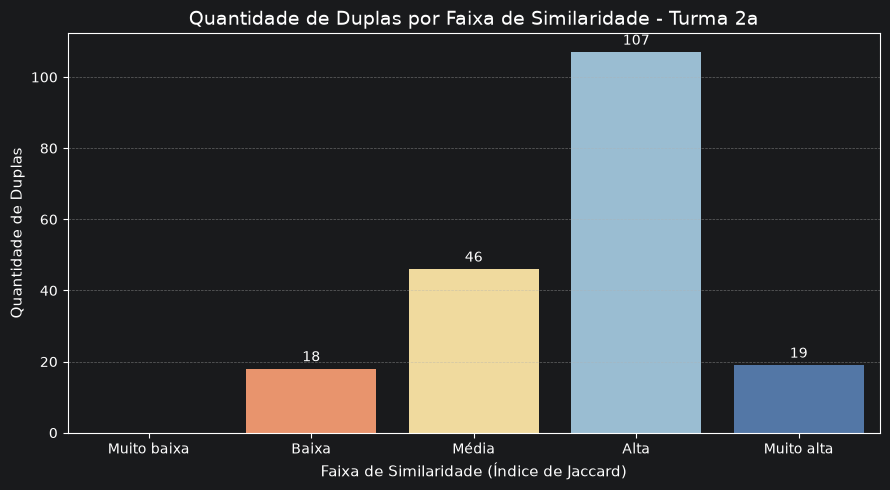


                 PROCESSANDO TURMA: 2b (N = 23)


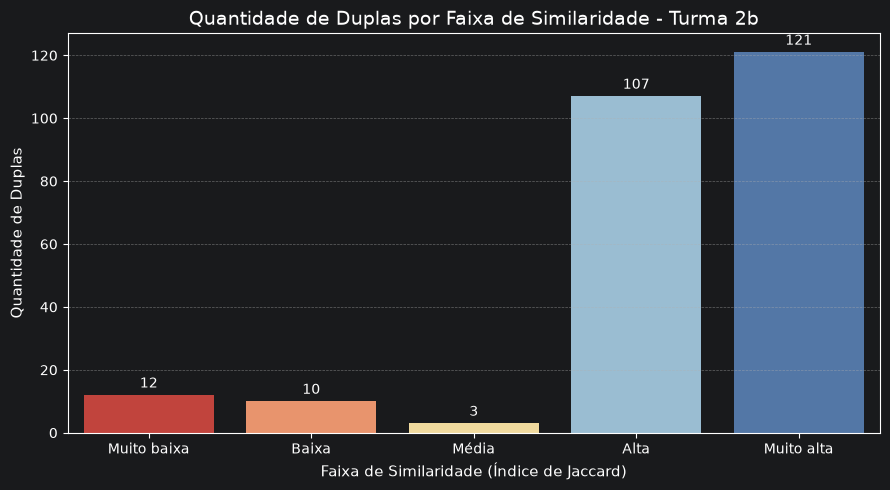


                 PROCESSANDO TURMA: 2c (N = 35)


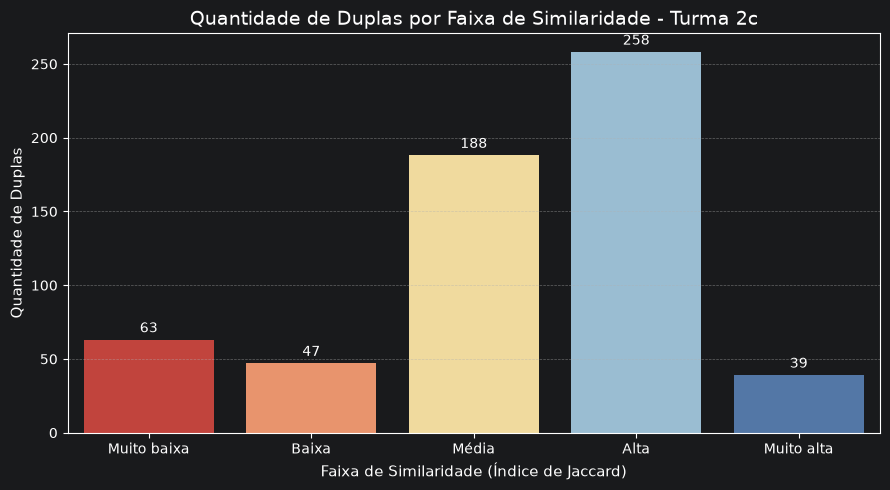


                 PROCESSANDO TURMA: 2d (N = 31)


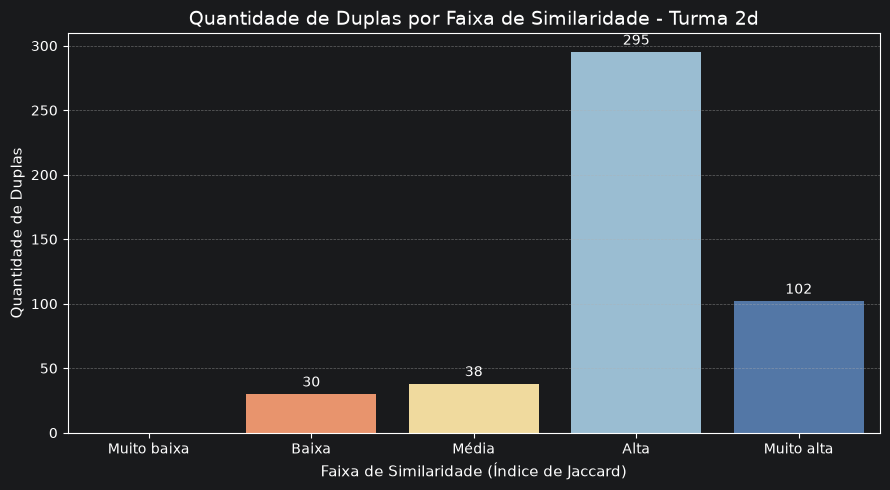

In [16]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 0. Configurações Globais do Pandas para o PyCharm / Jupyter
# Evita o corte de colunas e textos longos na exibição
# ---------------------------------------------------------
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)
pd.set_option('display.expand_frame_repr', False)

# 1. Caminho Fixo do Arquivo de Dados
file_path = 'data/prova_cn.csv'
df = pd.read_csv(file_path)

# Identificação das colunas das questões (excluindo metadados)
metadata_cols = ['estudante', 'datetime', 'carimbo_entrega', 'pontuacao', 'serie_turma', 'materia']
question_cols = [col for col in df.columns if col not in metadata_cols]

print(f"Arquivo carregado: {file_path}")
print(f"Total de estudantes: {len(df)}")
print(f"Turmas encontradas: {df['serie_turma'].unique().tolist()}")
print(f"Questões analisadas ({len(question_cols)}): {question_cols}\n")

# ---------------------------------------------------------
# 2. Função para Cálculo do Índice de Jaccard Categórico
# ---------------------------------------------------------

def jaccard_similarity_categorical(u, v):
    """
    Calcula a similaridade de Jaccard entre vetores de respostas categóricas:
    Intersection / Union = (Número de respostas idênticas) / (Total de questões)
    """
    return np.sum(u == v) / len(u)

# Definição das faixas de similaridade
bins = [-0.001, 0.2, 0.4, 0.6, 0.8, 1.001]
labels = ['Muito baixa', 'Baixa', 'Média', 'Alta', 'Muito alta']
paleta_cores = ['#d73027', '#fc8d59', '#fee090', '#91bfdb', '#4575b4']

# ---------------------------------------------------------
# 3. Processamento Estritamente Intra-Turma
# ---------------------------------------------------------

for turma, grupo in df.groupby('serie_turma'):
    students = grupo['estudante'].values
    respostas = grupo[question_cols].values
    n = len(students)

    if n < 2:
        print(f"\n--- Turma {turma}: Menos de 2 estudantes (sem duplas para comparar). ---")
        continue

    print(f"\n=========================================================")
    print(f"                 PROCESSANDO TURMA: {turma} (N = {n})")
    print(f"=========================================================")

    # A) Construção da Matriz de Similaridade da Turma
    matriz = np.zeros((n, n))
    pairs_list = []

    for i in range(n):
        for j in range(n):
            matriz[i, j] = jaccard_similarity_categorical(respostas[i], respostas[j])

    # Extração das duplas da turma (i < j)
    for i in range(n):
        for j in range(i + 1, n):
            pairs_list.append({
                'estudante_1': students[i],
                'estudante_2': students[j],
                'jaccard_similarity': matriz[i, j]
            })

    df_pairs_turma = pd.DataFrame(pairs_list)
    df_pairs_turma['categoria_similaridade'] = pd.cut(
        df_pairs_turma['jaccard_similarity'],
        bins=bins,
        labels=labels,
        right=True
    )

    # B) Gráfico de Barras por Turma (Quantidade de Duplas por Faixa de Similaridade)
    cat_counts = df_pairs_turma['categoria_similaridade'].value_counts().reindex(labels, fill_value=0)

    plt.figure(figsize=(9, 5))
    ax = sns.barplot(
        x=cat_counts.index,
        y=cat_counts.values,
        hue=cat_counts.index,
        palette=paleta_cores
    )
    plt.title(f'Quantidade de Duplas por Faixa de Similaridade - Turma {turma}', fontsize=14)
    plt.xlabel('Faixa de Similaridade (Índice de Jaccard)', fontsize=11)
    plt.ylabel('Quantidade de Duplas', fontsize=11)

    # Rótulo numérico no topo de cada barra
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f'{int(height)}',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=10, xytext=(0, 3),
                        textcoords='offset points')

    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    # C) Tabela da Turma Onde Cada Estudante Ocupa Uma Linha
    student_rows = []

    for i in range(n):
        est_id = students[i]
        seq_resp = "-".join(map(str, respostas[i]))

        peers_alta = []
        peers_muito_alta = []

        for j in range(n):
            if i == j:
                continue  # Ignora a auto-comparação

            sim_score = matriz[i, j]
            peer_id = students[j]

            # Classificação de similaridade nas faixas especificadas
            if 0.8 < sim_score <= 1.0:
                peers_muito_alta.append(f"{peer_id} ({sim_score:.2f})")
            elif 0.6 < sim_score <= 0.8:
                peers_alta.append(f"{peer_id} ({sim_score:.2f})")

    df_estudantes_turma = pd.DataFrame(student_rows)

    # D) Exibição da Tabela Filtrada por Turma
    if not df_estudantes_turma.empty:
        df_estudantes_turma['sequencia_estudante'] = range(1, len(df_estudantes_turma) + 1)

        colunas_ordenadas = [
            'sequencia_estudante',
            'serie_turma',
            'estudante',
            'sequencia_respostas',
            'duplas_alta_0.6_a_0.8',
            'duplas_muito_alta_0.8_a_1.0',
            'total_duplas_destaque'
        ]
        df_estudantes_turma = df_estudantes_turma[colunas_ordenadas]

        print(f"\n--- Tabela da Turma {turma} (Estudantes com Similaridade Alta / Muito Alta) ---")
        print(f"Total de estudantes listados: {len(df_estudantes_turma)}")
        display(df_estudantes_turma)

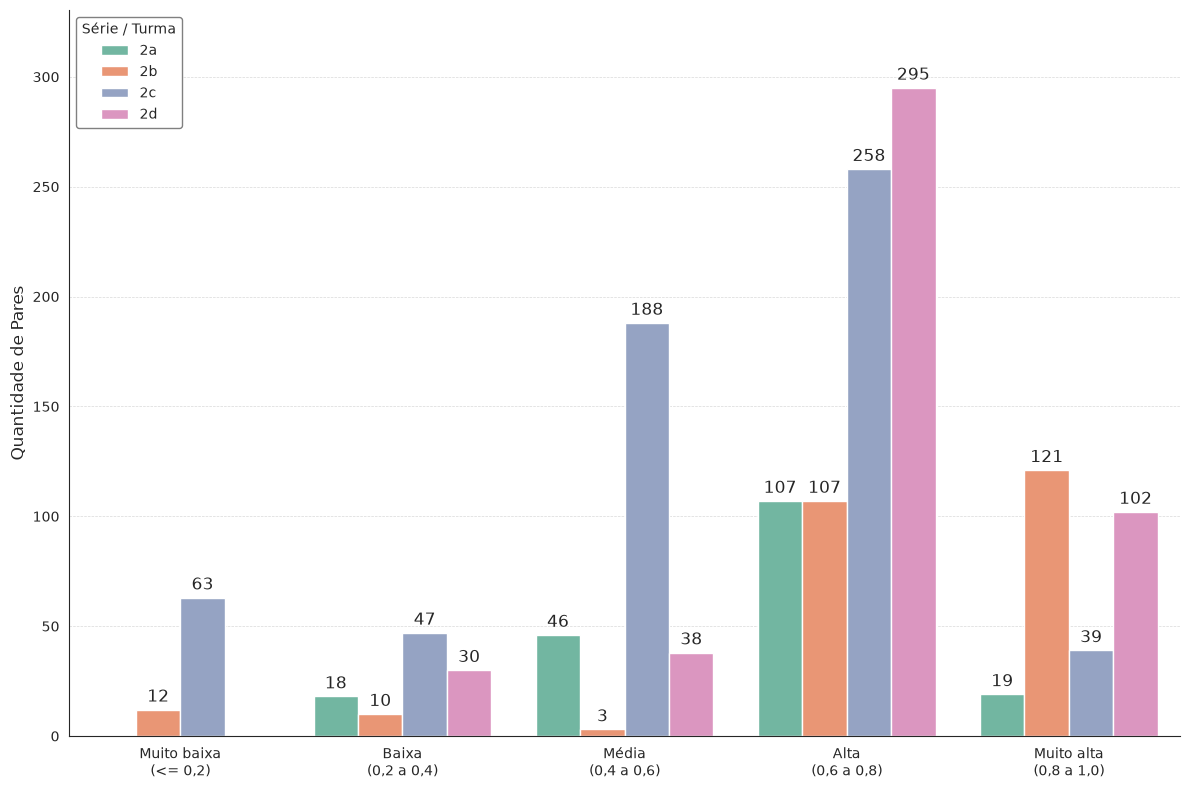

In [84]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Caminho do arquivo de dados
file_path = 'data/prova_cn.csv'
df = pd.read_csv(file_path)

# Identificação das colunas das questões
metadata_cols = ['estudante', 'datetime', 'carimbo_entrega', 'pontuacao', 'serie_turma', 'materia']
question_cols = [col for col in df.columns if col not in metadata_cols]

# 2. Função de similaridade
def jaccard_similarity_categorical(u, v):
    return np.sum(u == v) / len(u)

bins = [-0.001, 0.2, 0.4, 0.6, 0.8, 1.001]
labels = ['Muito baixa\n(<= 0,2)', 'Baixa\n(0,2 a 0,4)', 'Média\n(0,4 a 0,6)', 'Alta\n(0,6 a 0,8)', 'Muito alta\n(0,8 a 1,0)']

# 3. Processamento intra-turma
pairs_list = []
for turma, grupo in df.groupby('serie_turma'):
    students = grupo['estudante'].values
    respostas = grupo[question_cols].values
    n = len(students)
    if n < 2:
        continue

    for i in range(n):
        for j in range(i + 1, n):
            sim_score = jaccard_similarity_categorical(respostas[i], respostas[j])
            pairs_list.append({
                'serie_turma': turma,
                'estudante_1': students[i],
                'estudante_2': students[j],
                'jaccard_similarity': sim_score
            })

df_pairs = pd.DataFrame(pairs_list)
df_pairs['categoria_similaridade'] = pd.cut(
    df_pairs['jaccard_similarity'],
    bins=bins,
    labels=labels,
    right=True
)

df_counts = df_pairs.groupby(
    ['categoria_similaridade', 'serie_turma'],
    observed=False
).size().reset_index(name='quantidade_duplas')

# ---------------------------------------------------------
# 4. Configuração de Estilo e Ajustes de Cor
# ---------------------------------------------------------
# Configura o tema do Seaborn para fundo branco sem cinzento padrão
sns.set_style("white")

# Define a figura e os eixos com fundo totalmente branco
fig, ax = plt.subplots(figsize=(12, 8), facecolor='white')
ax.set_facecolor('white')

# Desenha as barras com uma paleta de cores harmoniosa (ex: 'Set2', 'tab10' ou 'deep')
sns.barplot(
    data=df_counts,
    x='categoria_similaridade',
    y='quantidade_duplas',
    hue='serie_turma',
    palette='Set2',
    ax=ax
)

plt.title('', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('', fontsize=12)
plt.ylabel('Quantidade de Pares', fontsize=12)

# Legenda ajustada com fundo branco opaco e moldura cinzenta sutil
plt.legend(
    title='Série / Turma',
    loc='upper left',
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    framealpha=1.0
)

# Grelha horizontal suave
plt.grid(axis='y', linestyle='--', alpha=0.3, color='gray')

# Expande o limite do eixo Y para que os números mais altos não fiquem colados ao topo
plt.ylim(0, df_counts['quantidade_duplas'].max() * 1.12)

# Rótulos numéricos destacados acima de cada barra
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=12,
            xytext=(0, 3),
            textcoords='offset points'
        )

# Remove as linhas de borda superior e direita
sns.despine()

plt.tight_layout()
plt.show()

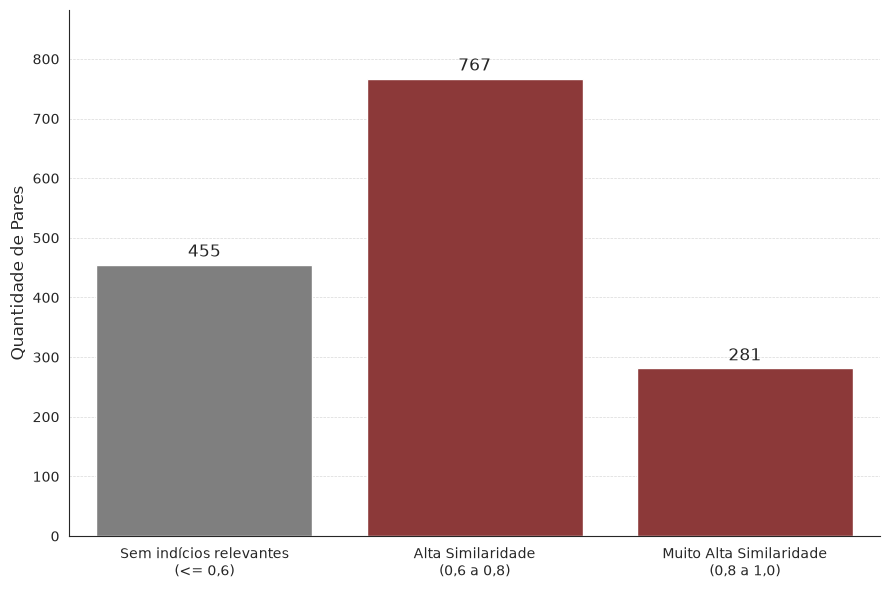

In [87]:
# ---------------------------------------------------------
# 5. GRÁFICO 2: Consolidação Geral em 3 Barras (Cinza e Vermelhos)
# ---------------------------------------------------------
labels = ['Muito baixa\n(<= 0,2)', 'Baixa\n(0,2 a 0,4)', 'Média\n(0,4 a 0,6)', 'Alta\n(0,6 a 0,8)', 'Muito alta\n(0,8 a 1,0)']
# Agrupa em Padrão Esperado (<=0.6), Alta (0.6-0.8) e Muito alta (0.8-1.0)
def classificar_nivel(categoria):
    if categoria in ['Muito baixa\n(<= 0,2)', 'Baixa\n(0,2 a 0,4)', 'Média\n(0,4 a 0,6)']:
        return 'Sem indícios relevantes\n(<= 0,6)'
    elif categoria == 'Alta\n(0,6 a 0,8)':
        return 'Alta Similaridade\n(0,6 a 0,8)'
    elif categoria == 'Muito alta\n(0,8 a 1,0)':
        return 'Muito Alta Similaridade\n(0,8 a 1,0)'

df_pairs['nivel_grupo'] = df_pairs['categoria_similaridade'].apply(classificar_nivel)

# Contagem total consolidada (sem separação por turma)
df_total = df_pairs['nivel_grupo'].value_counts().reindex([
    'Sem indícios relevantes\n(<= 0,6)',
    'Alta Similaridade\n(0,6 a 0,8)',
    'Muito Alta Similaridade\n(0,8 a 1,0)'
]).reset_index()

df_total.columns = ['categoria', 'quantidade_duplas']

fig2, ax2 = plt.subplots(figsize=(9, 6), facecolor='white')
ax2.set_facecolor('white')

# Definição das cores: 1 Cinza para o Padrão Esperado e 2 Vermelhos para os níveis de destaque
cores_3_barras = ['#7f7f7f', '#9a2b2b', '#9a2b2b']

sns.barplot(
    data=df_total,
    x='categoria',
    y='quantidade_duplas',
    hue='categoria',
    palette=cores_3_barras,
    ax=ax2
)

plt.title('', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('', fontsize=12)
plt.ylabel('Quantidade de Pares', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.3, color='gray')
plt.ylim(0, df_total['quantidade_duplas'].max() * 1.15)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=12,
            xytext=(0, 3),
            textcoords='offset points'
        )

sns.despine()
plt.tight_layout()
plt.show()

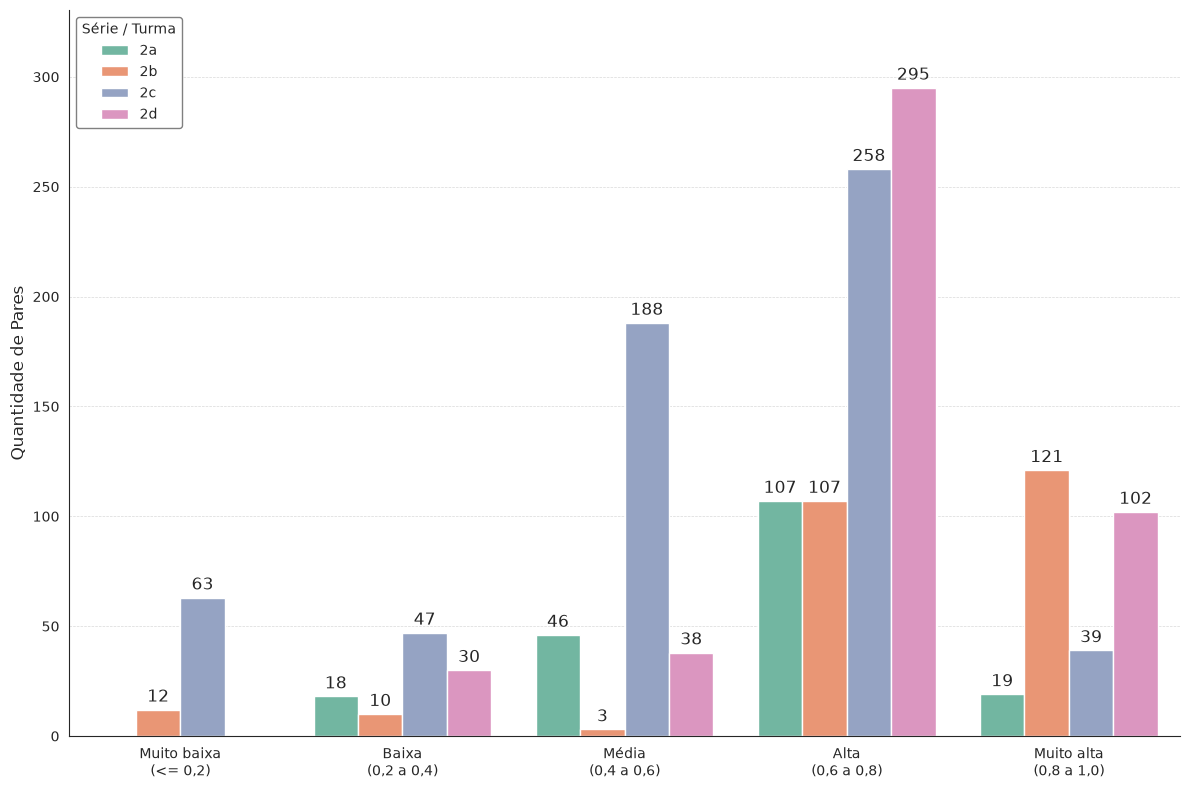

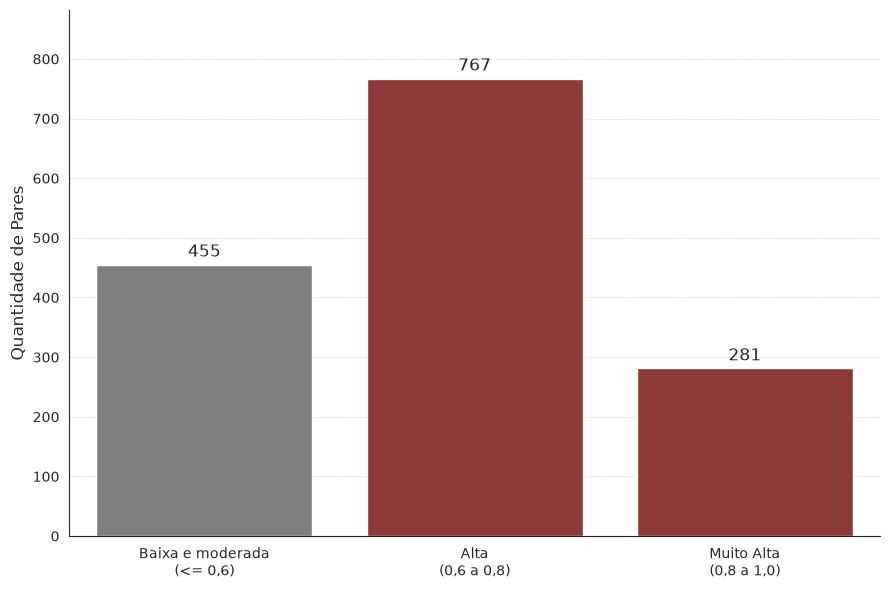

In [95]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Carregamento dos Dados e Definição de Colunas
# ---------------------------------------------------------
file_path = 'data/prova_cn.csv' if os.path.exists('data/prova_cn.csv') else 'prova_cn.csv'
df = pd.read_csv(file_path)

# Identificação dinâmica das colunas das questões
metadata_cols = {'estudante', 'datetime', 'carimbo_entrega', 'pontuacao', 'serie_turma', 'materia'}
question_cols = [col for col in df.columns if col not in metadata_cols]

# ---------------------------------------------------------
# 2. Funções para Cálculo da Similaridade de Jaccard
# ---------------------------------------------------------
def jaccard_similarity_categorical(respostas_a, respostas_b):
    """Calcula a taxa de concordância de Jaccard entre dois vetores de respostas."""
    return np.sum(respostas_a == respostas_b) / len(respostas_a)

def processar_pares_intra_turma(data, q_cols):
    """Calcula o índice de Jaccard exclusivamente para pares de estudantes da mesma turma."""
    pairs = []

    for turma, grupo in data.groupby('serie_turma'):
        estudantes = grupo['estudante'].values
        respostas = grupo[q_cols].values
        n = len(estudantes)

        if n < 2:
            continue

        # Combinação triangular para evitar auto-comparação e duplicações
        for i in range(n):
            for j in range(i + 1, n):
                sim_score = jaccard_similarity_categorical(respostas[i], respostas[j])
                pairs.append({
                    'serie_turma': turma,
                    'estudante_1': estudantes[i],
                    'estudante_2': estudantes[j],
                    'jaccard_similarity': sim_score
                })

    return pd.DataFrame(pairs)

# Execução do cálculo
df_pairs = processar_pares_intra_turma(df, question_cols)

# Classificação em 5 faixas categóricas de similaridade
bins_5 = [-0.001, 0.2, 0.4, 0.6, 0.8, 1.001]
labels_5 = [
    'Muito baixa\n(<= 0,2)',
    'Baixa\n(0,2 a 0,4)',
    'Média\n(0,4 a 0,6)',
    'Alta\n(0,6 a 0,8)',
    'Muito alta\n(0,8 a 1,0)'
]

df_pairs['categoria_similaridade'] = pd.cut(
    df_pairs['jaccard_similarity'],
    bins=bins_5,
    labels=labels_5,
    right=True
)

# ---------------------------------------------------------
# 3. Funções Auxiliares de Estilização Visual
# ---------------------------------------------------------
def adicionar_rotulos_barras(ax, fontsize=12):
    """Aplica rótulos numéricos sobre cada barra do gráfico."""
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(
                f'{int(height)}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=fontsize,
                xytext=(0, 3),
                textcoords='offset points'
            )

sns.set_style("white")

# ---------------------------------------------------------
# 4. GRÁFICO 1: Quantidade de Pares por Faixa e Turma
# ---------------------------------------------------------
df_counts = df_pairs.groupby(
    ['categoria_similaridade', 'serie_turma'],
    observed=False
).size().reset_index(name='quantidade_duplas')

fig1, ax1 = plt.subplots(figsize=(12, 8), facecolor='white')
ax1.set_facecolor('white')

sns.barplot(
    data=df_counts,
    x='categoria_similaridade',
    y='quantidade_duplas',
    hue='serie_turma',
    palette='Set2',
    ax=ax1
)

plt.xlabel('', fontsize=12)
plt.ylabel('Quantidade de Pares', fontsize=12)
plt.legend(
    title='Série / Turma',
    loc='upper left',
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    framealpha=1.0
)
plt.grid(axis='y', linestyle='--', alpha=0.3, color='gray')
plt.ylim(0, df_counts['quantidade_duplas'].max() * 1.12)

adicionar_rotulos_barras(ax1)
sns.despine()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. GRÁFICO 2: Consolidação Geral em 3 Barras (Cinza e Vermelhos)
# ---------------------------------------------------------
def classificar_nivel_consolidado(cat):
    if cat in ['Muito baixa\n(<= 0,2)', 'Baixa\n(0,2 a 0,4)', 'Média\n(0,4 a 0,6)']:
        return 'Baixa e moderada\n(<= 0,6)'
    elif cat == 'Alta\n(0,6 a 0,8)':
        return 'Alta\n(0,6 a 0,8)'
    elif cat == 'Muito alta\n(0,8 a 1,0)':
        return 'Muito Alta\n(0,8 a 1,0)'

df_pairs['nivel_grupo'] = df_pairs['categoria_similaridade'].apply(classificar_nivel_consolidado)

labels_3 = [
    'Baixa e moderada\n(<= 0,6)',
    'Alta\n(0,6 a 0,8)',
    'Muito Alta\n(0,8 a 1,0)'
]

df_total = df_pairs['nivel_grupo'].value_counts().reindex(labels_3).reset_index()
df_total.columns = ['categoria', 'quantidade_duplas']

fig2, ax2 = plt.subplots(figsize=(9, 6), facecolor='white')
ax2.set_facecolor('white')

# Paleta personalizada: Cinza (#7f7f7f), Vermelho (#d9534f) e Vermelho-Escuro (#9a2b2b)
cores_3_barras = ['#7f7f7f', '#9a2b2b', '#9a2b2b']

sns.barplot(
    data=df_total,
    x='categoria',
    y='quantidade_duplas',
    hue='categoria',
    palette=cores_3_barras,
    ax=ax2
)

plt.xlabel('', fontsize=12)
plt.ylabel('Quantidade de Pares', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3, color='gray')
plt.ylim(0, df_total['quantidade_duplas'].max() * 1.15)

adicionar_rotulos_barras(ax2)
sns.despine()
plt.tight_layout()
plt.show()